In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

In [2]:
class Problem:
    def __init__(self, path="../data/TSPA.csv"):
        self.df = pd.read_csv(path, sep=";", header=None)

        cord = self.df.values[:, :-1]
        dist = np.sqrt(np.sum((cord[None, :, :] - cord[:, None, :]) ** 2, axis=2))

        self.dist = np.floor(dist + 0.5).astype(np.int64)
        self.cost = np.ascontiguousarray(self.df.values[:, -1], dtype=np.int64)

    def get_n(self):
        return len(self.df)

    def get_n_nodes(self):
        # 50% of the nodes, rounded up
        return (self.get_n() + 1) // 2

    def eval(self, nodes: np.array, end=True):
        assert nodes.dtype == np.int64
        assert len(set(nodes)) == len(nodes)

        n_nodes = self.get_n_nodes()
        if end == True and len(nodes) != n_nodes:
            raise ValueError("The final path does not have the required length!")

        pairs = np.column_stack((nodes, np.roll(nodes, -1)))
        if not end:
            pairs = pairs[:-1]
        total_length = np.sum(self.dist[pairs[:, 0], pairs[:, 1]])
        total_cost = np.sum(self.cost[nodes])

        return total_length + total_cost

## Construction heuristics from assignments 1 and 2

The same algorithms as before (same solutions, same tie breaking), rewritten with numba so that the running times of all methods are comparable. NN (any position), greedy cycle and both regret heuristics use one function, as in assignment 2:

`score = w_regret * regret - w_greedy * best_delta`, the node with the highest score is inserted at its best position (ties: smaller best delta, then lower node index).

In [3]:
BIG = 1 << 62


def random_solution(n, n_nodes):
    return np.random.choice(n, size=n_nodes, replace=False)


@njit
def nearest_neighbor_end(d, cost, start, n_nodes):
    n = len(cost)
    path = np.empty(n_nodes, dtype=np.int64)
    used = np.zeros(n, dtype=np.bool_)
    path[0] = start
    used[start] = True

    for size in range(1, n_nodes):
        last = path[size - 1]
        best, best_j = BIG, -1
        for j in range(n):
            if not used[j] and d[last, j] + cost[j] < best:
                best, best_j = d[last, j] + cost[j], j
        path[size] = best_j
        used[best_j] = True

    return path


@njit
def regret_heuristic(d, cost, start, n_nodes, cycle, w_regret, w_greedy):
    n = len(cost)
    sol = np.empty(n_nodes, dtype=np.int64)
    used = np.zeros(n, dtype=np.bool_)
    sol[0] = start
    used[start] = True
    size = 1

    if cycle:
        # same start as greedy cycle: the second node closes a 2-node cycle
        best, second = BIG, -1
        for j in range(n):
            if j != start and 2 * d[start, j] + cost[j] < best:
                best, second = 2 * d[start, j] + cost[j], j
        sol[1] = second
        used[second] = True
        size = 2

    while size < n_nodes:
        best_score, best_delta, best_j, best_pos = -np.inf, BIG, -1, -1

        for j in range(n):
            if used[j]:
                continue

            # best and second best insertion cost of node j
            b1, b2, pos1 = BIG, BIG, -1
            n_pos = size if cycle else size + 1
            for i in range(n_pos):
                if cycle:
                    a, b = sol[i - 1] if i > 0 else sol[size - 1], sol[i]
                    delta = d[a, j] + d[j, b] - d[a, b]
                elif i == 0:
                    delta = d[j, sol[0]]
                elif i == size:
                    delta = d[sol[size - 1], j]
                else:
                    a, b = sol[i - 1], sol[i]
                    delta = d[a, j] + d[j, b] - d[a, b]
                delta += cost[j]

                if delta < b1:
                    b1, b2, pos1 = delta, b1, i
                elif delta < b2:
                    b2 = delta
            if n_pos == 1:
                b2 = b1

            score = w_regret * (b2 - b1) - w_greedy * b1
            if score > best_score or (score == best_score and b1 < best_delta):
                best_score, best_delta, best_j, best_pos = score, b1, j, pos1

        sol[best_pos + 1:size + 1] = sol[best_pos:size].copy()
        sol[best_pos] = best_j
        used[best_j] = True
        size += 1

    return sol


def nearest_neighbor_any(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, False, 0.0, 1.0)

def greedy_cycle(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, True, 0.0, 1.0)

def regret_nn_any(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, False, 1.0, 0.0)

def regret_greedy_cycle(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, True, 1.0, 0.0)

def weighted_regret_nn_any(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, False, 1.0, 1.0)

def weighted_regret_greedy_cycle(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, True, 1.0, 1.0)


constructions = {
    "NN (end only)": nearest_neighbor_end,
    "NN (any position)": nearest_neighbor_any,
    "Greedy cycle": greedy_cycle,
    "2-regret (NN any position)": regret_nn_any,
    "2-regret (greedy cycle)": regret_greedy_cycle,
    "Weighted 2-regret (NN any position)": weighted_regret_nn_any,
    "Weighted 2-regret (greedy cycle)": weighted_regret_greedy_cycle,
}

## Moves and deltas

The neighborhood that was the best in assignment 3: inter-route moves and two-edges exchange. A solution is kept as two arrays: `sol` - the cycle (selected nodes in order) and `unsel` - the nodes that are not selected. A move is evaluated only by its delta (change of the objective), the neighbor solution is never built.

- Inter-route move `(i, k)`: replace the selected node `sol[i]` with the not selected node `unsel[k]` (at the same place in the cycle). Two edges and the node cost change.
- Intra-route two-edges exchange `(i, j)`: remove edges `(sol[i], sol[i+1])` and `(sol[j], sol[j+1])`, add `(sol[i], sol[j])` and `(sol[i+1], sol[j+1])`, i.e. reverse `sol[i+1..j]`. Pairs of edges with a common node are skipped (they give the same solution).

In [ ]:
@njit
def delta_inter(d, cost, sol, unsel, i, k):
    n = len(sol)
    p, u, nx, v = sol[i - 1], sol[i], sol[(i + 1) % n], unsel[k]
    return d[p, v] + d[v, nx] - d[p, u] - d[u, nx] + cost[v] - cost[u]


@njit
def delta_two_edges(d, sol, i, j):
    n = len(sol)
    a1, a2, b1, b2 = sol[i], sol[i + 1], sol[j], sol[(j + 1) % n]
    return d[a1, b1] + d[a2, b2] - d[a1, a2] - d[b1, b2]


@njit
def apply_two_edges(sol, i, j):
    sol[i + 1:j + 1] = sol[i + 1:j + 1][::-1].copy()


def intra_moves(n_nodes):
    # all pairs of positions (i, j), i < j, without two edges with a common node
    pairs = [(i, j) for i in range(n_nodes) for j in range(i + 2, n_nodes) if not (i == 0 and j == n_nodes - 1)]
    pairs = np.array(pairs, dtype=np.int64)
    return pairs[:, 0].copy(), pairs[:, 1].copy()

## Candidate moves

For each node `a` we determine its `N_NEAR = 10` "nearest" nodes - the nodes `b` with the smallest `d(a, b) + cost(b)`. An edge `(a, b)` with a selected node `a` and `b` from the nearest nodes of `a` is a candidate edge. A candidate move is a move that adds at least one candidate edge to the solution. There are two such moves for each candidate edge:

- `b` is selected (two-edges exchange): remove the edges after `a` and after `b`, i.e. `(a, next(a))` and `(b, next(b))`, or the edges before `a` and before `b`, i.e. `(prev(a), a)` and `(prev(b), b)`. In both cases `(a, b)` is one of the two added edges.
- `b` is not selected (inter-route move): `b` replaces the next node of `a` (added edges `(a, b)` and `(b, next(next(a)))`) or the previous node of `a` (added edges `(prev(prev(a)), b)` and `(b, a)`). Replacing `a` itself with `b` would not add the edge `(a, b)`.

We iterate only over the candidate moves: the first loop goes over the selected nodes `a`, the second over the nearest nodes `b` of `a`. To know in O(1) if `b` is selected and where it is, we keep the array `pos` (position of each node in `sol` or in `unsel`) and update it after each performed move. The same move can be evaluated twice (from both ends of its candidate edges), it does not change the result.

In [5]:
N_NEAR = 10


def nearest_nodes(d, cost, n_near):
    # for each node: the n_near other nodes with the smallest d[a, b] + cost[b]
    score = d + cost[None, :]
    np.fill_diagonal(score, BIG)
    return np.ascontiguousarray(np.argsort(score, axis=1, kind="stable")[:, :n_near])

## Local search

Both versions return the number of performed moves, the number of evaluated moves and the sum of the deltas of the performed moves (used to check that the deltas are correct).

**Steepest** (baseline, the same as in assignment 3): in each iteration all moves (inter-route and intra-route together) are evaluated and the best one is performed, as long as it improves the solution.

**Steepest with candidate moves**: in each iteration only the candidate moves are evaluated and the best one is performed, as long as it improves the solution.

In [6]:
@njit
def steepest_ls(d, cost, sol, unsel, move_i, move_j):
    n, m = len(sol), len(unsel)
    iters, evals, total = 0, 0, 0

    while True:
        best, kind, bi, bj = 0, -1, 0, 0
        for i in range(n):
            for k in range(m):
                delta = delta_inter(d, cost, sol, unsel, i, k)
                if delta < best:
                    best, kind, bi, bj = delta, 0, i, k
        for q in range(len(move_i)):
            delta = delta_two_edges(d, sol, move_i[q], move_j[q])
            if delta < best:
                best, kind, bi, bj = delta, 1, move_i[q], move_j[q]
        evals += n * m + len(move_i)

        if kind == -1:
            return iters, evals, total
        if kind == 0:
            sol[bi], unsel[bj] = unsel[bj], sol[bi]
        else:
            apply_two_edges(sol, bi, bj)
        iters += 1
        total += best


@njit
def steepest_ls_candidates(d, cost, sol, unsel, near):
    n, m = len(sol), len(unsel)
    n_near = near.shape[1]
    # position of each node in sol (if selected) or in unsel (if not selected)
    selected = np.zeros(len(cost), dtype=np.bool_)
    pos = np.empty(len(cost), dtype=np.int64)
    for i in range(n):
        selected[sol[i]] = True
        pos[sol[i]] = i
    for k in range(m):
        pos[unsel[k]] = k
    iters, evals, total = 0, 0, 0

    while True:
        best, kind, bi, bj = 0, -1, 0, 0
        for i in range(n):
            for t in range(n_near):
                b = near[sol[i], t]
                j = pos[b]
                if selected[b]:
                    # s = 0: remove the edges after a and after b, s = 1: the edges before them
                    for s in range(2):
                        x = i - s if i - s >= 0 else n - 1
                        y = j - s if j - s >= 0 else n - 1
                        lo, hi = min(x, y), max(x, y)
                        if hi - lo < 2 or (lo == 0 and hi == n - 1):
                            continue
                        delta = delta_two_edges(d, sol, lo, hi)
                        evals += 1
                        if delta < best:
                            best, kind, bi, bj = delta, 1, lo, hi
                else:
                    # s = 0: b replaces the next node of a, s = 1: the previous node
                    for s in range(2):
                        r = i + 1 if s == 0 else i - 1
                        if r == n:
                            r = 0
                        elif r < 0:
                            r = n - 1
                        delta = delta_inter(d, cost, sol, unsel, r, j)
                        evals += 1
                        if delta < best:
                            best, kind, bi, bj = delta, 0, r, j

        if kind == -1:
            return iters, evals, total
        if kind == 0:
            u, v = sol[bi], unsel[bj]
            sol[bi], unsel[bj] = v, u
            selected[u], selected[v] = False, True
            pos[u], pos[v] = bj, bi
        else:
            apply_two_edges(sol, bi, bj)
            for q in range(bi + 1, bj + 1):
                pos[sol[q]] = q
        iters += 1
        total += best

## Experiment

All methods are timed in the same way (numba, compiled before the measurements). For the local search the running time includes building the starting solution. The nearest nodes depend only on the instance (like the distance matrix), so they are determined once for each instance, before the runs, and their time is reported separately.

Both local search methods start from the same 200 random solutions as in the "Random" row (the same solutions as in assignment 3).

In [7]:
problems = {name: Problem(f"../data/{name}.csv") for name in ["TSPA", "TSPB"]}

# compile all numba functions before the measurements
p = problems["TSPA"]
k = p.get_n_nodes()
for f in constructions.values():
    f(p.dist, p.cost, 0, k)
move_i, move_j = intra_moves(k)
sol = random_solution(p.get_n(), k)
steepest_ls(p.dist, p.cost, sol, np.setdiff1d(np.arange(p.get_n()), sol), move_i, move_j)
sol = random_solution(p.get_n(), k)
steepest_ls_candidates(p.dist, p.cost, sol, np.setdiff1d(np.arange(p.get_n()), sol), nearest_nodes(p.dist, p.cost, N_NEAR))

(125, 226318, -179439)

In [8]:
np.random.seed(0)
results = {}
random_solutions = {}

for name, p in problems.items():
    n, k = p.get_n(), p.get_n_nodes()

    values, times, sols = [], [], []
    for _ in range(200):
        t0 = time.perf_counter()
        s = random_solution(n, k)
        times.append(time.perf_counter() - t0)
        values.append(p.eval(s))
        sols.append(s)
    random_solutions[name] = sols
    results[("Random", name)] = {"values": np.array(values), "times": np.array(times), "best": sols[int(np.argmin(values))]}

    for method, f in constructions.items():
        values, times, sols = [], [], []
        for start in range(n):
            t0 = time.perf_counter()
            s = f(p.dist, p.cost, start, k)
            times.append(time.perf_counter() - t0)
            values.append(p.eval(s))
            sols.append(s)
        results[(method, name)] = {"values": np.array(values), "times": np.array(times), "best": sols[int(np.argmin(values))]}

In [9]:
ls_methods = [
    "Steepest LS, two-edges exchange, random start",
    "Steepest LS, candidate moves, random start",
]
near_time = {}


for name, p in problems.items():
    n, k = p.get_n(), p.get_n_nodes()
    move_i, move_j = intra_moves(k)
    t0 = time.perf_counter()
    near = nearest_nodes(p.dist, p.cost, N_NEAR)
    near_time[name] = time.perf_counter() - t0

    for method in ls_methods:
        candidates = "candidate" in method
        values, times, sols, iters, evals = [], [], [], [], []

        for run in range(200):
            t0 = time.perf_counter()
            sol = random_solutions[name][run].copy()
            unsel = np.setdiff1d(np.arange(n), sol)
            t1 = time.perf_counter()
            start_value = p.eval(sol)

            t2 = time.perf_counter()
            if candidates:
                it, ev, total = steepest_ls_candidates(p.dist, p.cost, sol, unsel, near)
            else:
                it, ev, total = steepest_ls(p.dist, p.cost, sol, unsel, move_i, move_j)
            t3 = time.perf_counter()

            value = p.eval(sol)
            # the sum of the deltas must match the objective computed from scratch
            assert value == start_value + total
            values.append(value)
            times.append((t1 - t0) + (t3 - t2))
            sols.append(sol)
            iters.append(it)
            evals.append(ev)

        results[(method, name)] = {
            "values": np.array(values), "times": np.array(times), "best": sols[int(np.argmin(values))],
            "iters": np.array(iters), "evals": np.array(evals),
        }

## Results

In [10]:
methods = ["Random"] + list(constructions) + ls_methods


def summary(key, fmt_mean, fmt_range):
    # av (min – max) for each instance
    rows = []
    for method in methods:
        row = {"Method": method}
        for name in problems:
            v = results[(method, name)][key]
            row[name] = f"{fmt_mean(v.mean())} ({fmt_range(v.min())} – {fmt_range(v.max())})"
        rows.append(row)
    return pd.DataFrame(rows)


objective_table = summary("values", lambda x: f"{np.round(x, 2):.2f}", lambda x: f"{x}")
objective_table

,Method,TSPA,TSPB
0,Random,262874.39 (238989 – 290456),206009.68 (185119 – 225987)
1,NN (end only),87476.63 (84362 – 90075),59397.34 (56007 – 63166)
2,NN (any position),74346.96 (72328 – 77022),59475.50 (52915 – 66164)
3,Greedy cycle,73792.87 (72590 – 75345),59777.50 (55655 – 63736)
4,2-regret (NN any position),121360.29 (110950 – 135771),73649.84 (68761 – 79756)
5,2-regret (greedy cycle),120378.76 (112806 – 128089),72484.84 (68150 – 77274)
6,Weighted 2-regret (NN any position),75549.36 (72419 – 78504),55698.94 (50485 – 61406)
7,Weighted 2-regret (greedy cycle),73349.74 (72011 – 75532),57766.23 (52906 – 63326)
8,"Steepest LS, two-edges exchange, random start",76199.78 (74209 – 79975),52570.36 (50165 – 56169)
9,"Steepest LS, candidate moves, random start",80148.18 (76513 – 85021),52669.16 (50378 – 55491)


In [11]:
# running time in milliseconds
ms = lambda x: f"{1000 * x:.3f}"
time_table = summary("times", ms, ms)
print("determining the nearest nodes (once per instance):", {name: ms(t) for name, t in near_time.items()})
time_table

determining the nearest nodes (once per instance): {'TSPA': '1.702', 'TSPB': '1.238'}


,Method,TSPA,TSPB
0,Random,0.036 (0.013 – 0.167),0.016 (0.013 – 0.058)
1,NN (end only),0.035 (0.029 – 0.128),0.037 (0.029 – 0.180)
2,NN (any position),2.426 (2.107 – 4.328),2.324 (2.070 – 3.407)
3,Greedy cycle,2.282 (1.969 – 4.948),2.226 (1.931 – 4.277)
4,2-regret (NN any position),2.493 (2.128 – 4.445),2.623 (2.071 – 12.542)
5,2-regret (greedy cycle),2.232 (1.976 – 3.669),2.117 (1.925 – 3.503)
6,Weighted 2-regret (NN any position),2.414 (2.103 – 5.223),3.012 (2.064 – 13.440)
7,Weighted 2-regret (greedy cycle),2.267 (1.971 – 5.019),2.525 (1.943 – 8.383)
8,"Steepest LS, two-edges exchange, random start",9.074 (7.239 – 14.867),8.518 (7.060 – 13.264)
9,"Steepest LS, candidate moves, random start",3.028 (2.389 – 5.459),3.044 (2.274 – 5.371)


In [12]:
# average number of performed moves and of evaluated moves
rows = []
for method in ls_methods:
    row = {"Method": method}
    for name in problems:
        r = results[(method, name)]
        row[f"{name} moves"] = round(r["iters"].mean(), 1)
        row[f"{name} evaluated"] = round(r["evals"].mean())
    rows.append(row)
moves_table = pd.DataFrame(rows)
moves_table

,Method,TSPA moves,TSPA evaluated,TSPB moves,TSPB evaluated
0,"Steepest LS, two-edges exchange, random start",133.0,1990568,132.8,1987450
1,"Steepest LS, candidate moves, random start",124.9,226703,131.3,233449


## Solution check

Independent check of the best solutions: the right number of distinct nodes, the objective recomputed from scratch with plain loops, and for the local search methods - that the solution is really a local optimum. Every neighbor solution is built explicitly (all pairs of positions, all not selected nodes) and its objective is computed from scratch, without the delta functions and the move lists used by the local search. For the candidate moves only the neighbors that add a candidate edge are checked: the added edges are found by comparing the edge sets of the two solutions, and an added edge `(x, y)` is a candidate edge if `x` was selected and `y` is one of the nearest nodes of `x` (or the other way round).

In [13]:
def objective_from_scratch(p, nodes):
    nodes = [int(x) for x in nodes]
    length = sum(p.dist[nodes[i], nodes[(i + 1) % len(nodes)]] for i in range(len(nodes)))
    return length + sum(p.cost[x] for x in nodes)


def edge_set(nodes):
    nodes = [int(x) for x in nodes]
    return {frozenset((nodes[i], nodes[(i + 1) % len(nodes)])) for i in range(len(nodes))}


def is_local_optimum(p, sol, near=None):
    # all neighbors are built explicitly, without the delta functions and the move lists of the local search
    value = objective_from_scratch(p, sol)
    old_nodes, old_edges = set(sol.tolist()), edge_set(sol)

    def adds_candidate_edge(s):
        for x, y in map(tuple, edge_set(s) - old_edges):
            if (x in old_nodes and y in near[x]) or (y in old_nodes and x in near[y]):
                return True
        return False

    neighbors = []
    for i in range(len(sol)):
        for v in range(p.get_n()):
            if v in old_nodes:
                continue
            s = sol.copy()
            s[i] = v
            neighbors.append(s)
    for i in range(len(sol)):
        for j in range(i + 1, len(sol)):
            s = sol.copy()
            s[i + 1:j + 1] = s[i + 1:j + 1][::-1]
            neighbors.append(s)

    for s in neighbors:
        if near is not None and not adds_candidate_edge(s):
            continue
        if objective_from_scratch(p, s) < value:
            return False
    return True


for (method, name), r in results.items():
    p, s = problems[name], r["best"]
    assert len(s) == p.get_n_nodes() and len(set(s.tolist())) == len(s)
    assert all(0 <= x < p.get_n() for x in s)
    assert objective_from_scratch(p, s) == r["values"].min()

for method in ls_methods:
    for name, p in problems.items():
        near = None
        if "candidate" in method:
            near = [set(row.tolist()) for row in nearest_nodes(p.dist, p.cost, N_NEAR)]
        assert is_local_optimum(p, results[(method, name)]["best"], near)
print("All best solutions are valid, the local search solutions are local optima")

All best solutions are valid, the local search solutions are local optima


## Visualization

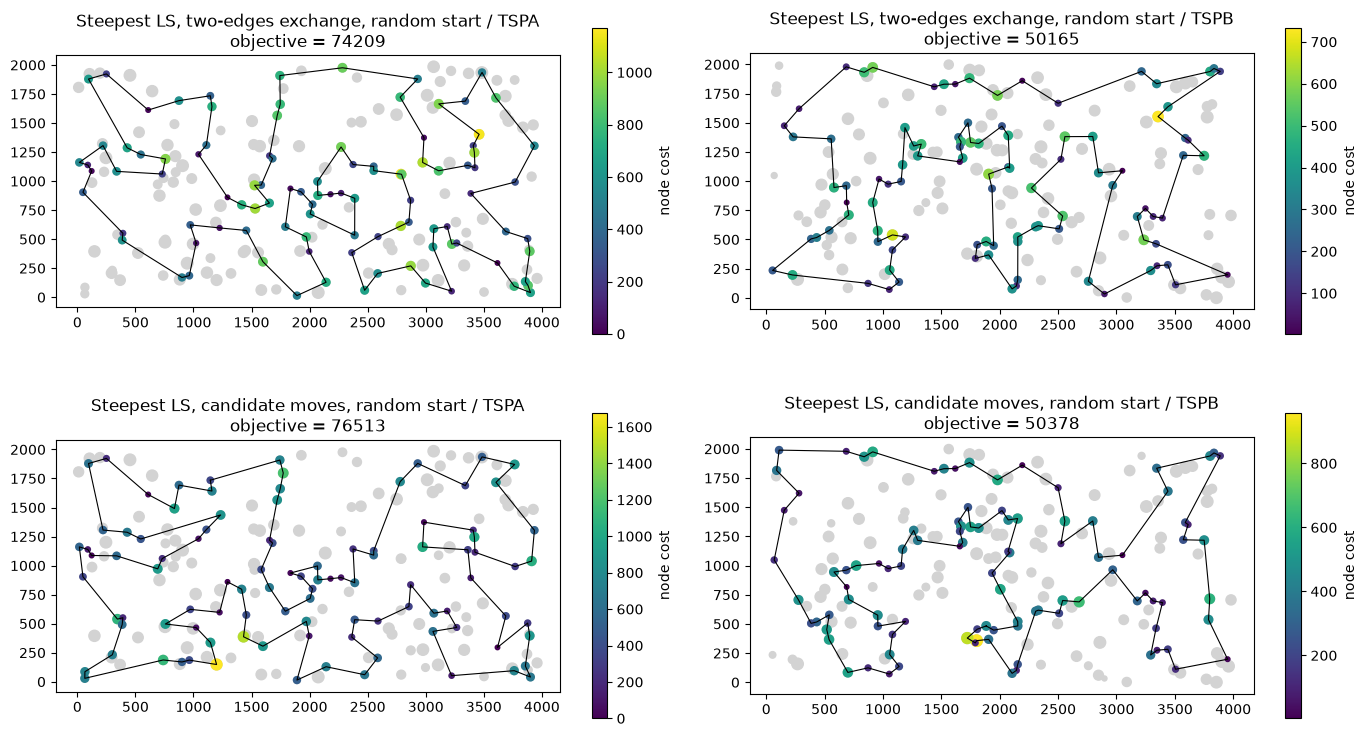

In [14]:
fig, axes = plt.subplots(len(ls_methods), len(problems), figsize=(7 * len(problems), 4 * len(ls_methods)), squeeze=False)

for col, (name, p) in enumerate(problems.items()):
    x, y, cost = p.df[0].values, p.df[1].values, p.df[2].values
    sizes = 10 + 60 * cost / cost.max()

    for row, method in enumerate(ls_methods):
        ax = axes[row, col]
        solution = results[(method, name)]["best"]
        cycle = np.append(solution, solution[0])

        # all nodes in gray, selected nodes colored by cost, size also by cost
        ax.scatter(x, y, s=sizes, c="lightgray")
        ax.plot(x[cycle], y[cycle], c="black", linewidth=0.8)
        points = ax.scatter(x[solution], y[solution], s=sizes[solution], c=cost[solution], cmap="viridis")

        ax.set_title(f"{method} / {name}\nobjective = {p.eval(solution)}")
        ax.set_aspect("equal")
        fig.colorbar(points, ax=ax, label="node cost", shrink=0.8)

fig.tight_layout()
fig.savefig("solutions.png", dpi=100)
plt.show()

## Best solutions

In [15]:
for method in ls_methods:
    for name, p in problems.items():
        s = results[(method, name)]["best"]
        print(f"{method} / {name} ({p.eval(s)}):")
        print(", ".join(str(x) for x in s))
        print()

Steepest LS, two-edges exchange, random start / TSPA (74209):
187, 30, 141, 87, 98, 114, 181, 135, 73, 45, 67, 144, 53, 140, 84, 131, 36, 177, 179, 52, 143, 33, 9, 54, 194, 8, 174, 176, 72, 134, 58, 192, 158, 138, 182, 57, 151, 150, 106, 42, 89, 107, 88, 78, 193, 153, 170, 159, 130, 93, 47, 147, 101, 29, 178, 184, 59, 1, 169, 50, 3, 85, 142, 164, 186, 136, 39, 115, 112, 139, 51, 16, 35, 156, 185, 102, 28, 180, 132, 76, 71, 157, 91, 80, 48, 31, 108, 152, 100, 123, 49, 60, 116, 149, 63, 168, 97, 127, 171, 2

Steepest LS, two-edges exchange, random start / TSPB (50165):
184, 3, 46, 72, 117, 8, 120, 133, 136, 172, 160, 69, 21, 183, 30, 130, 38, 47, 140, 154, 97, 155, 71, 141, 40, 60, 157, 45, 134, 175, 174, 1, 132, 29, 6, 115, 170, 125, 177, 158, 145, 28, 149, 116, 147, 42, 121, 198, 96, 48, 156, 89, 57, 190, 70, 81, 94, 105, 187, 18, 196, 114, 148, 10, 90, 129, 127, 80, 182, 153, 110, 2, 14, 20, 74, 171, 99, 192, 54, 162, 104, 185, 76, 27, 66, 67, 24, 34, 152, 181, 179, 87, 82, 51, 85, 59